<a href="https://colab.research.google.com/github/emiliano-ipa/CEIA-PLN-desafios/blob/main/Desafios/Desafio_2/Desafio_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Desafío 2 · Custom embeddings con Gensim
**Alumno:** Emiliano Iparraguirre



### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

### Objetivo
Entrenar embeddings de palabras con Word2Vec (Gensim) sobre un corpus propio, la saga de
d'Artagnan de Alexandre Dumas, para analizar cómo el autor usa las palabras. Se buscan
términos similares y opuestos, se prueban analogías, se proyectan los vectores a 2D y se
interpretan los grupos de palabras que se forman.

### 1 · Elección del corpus

Se eligió **la saga completa de d'Artagnan** (*The d'Artagnan Romances*), de Alexandre Dumas,
en su traducción al inglés disponible en Project Gutenberg (dominio público):

| # | Libro | Ebook Gutenberg |
|---|-------|-----------------|
| 1 | The Three Musketeers | 1257 |
| 2 | Twenty Years After | 1259 |
| 3 | The Vicomte de Bragelonne | 2609 |
| 4 | Ten Years Later | 2681 |
| 5 | Louise de la Vallière | 2710 |
| 6 | The Man in the Iron Mask | 2759 |

Los libros 3 a 6 son las cuatro partes en que la edición inglesa divide *Le Vicomte de Bragelonne*,
así que no hay texto duplicado entre volúmenes.

**Por qué este corpus:**
- **Volumen:** más de un millón de palabras. El ejemplo de clase (Beatles) tenía 1.846 líneas y un
  vocabulario de 445 palabras, con vecinos dominados por estribillos repetidos. Un corpus más grande
  y variado hace que cada palabra aparezca en muchos contextos distintos.
- **Estructura rica para clusters:** muchos personajes recurrentes (d'Artagnan, Athos, Porthos,
  Aramis), bandos políticos (el rey, Richelieu, Mazarino), títulos nobiliarios, lugares,
  armas y vocabulario militar. Eso permite esperar grupos semánticos interpretables.
- **Dominio público:** es una de las fuentes que sugiere la cátedra y el texto se puede
  descargar y redistribuir sin restricciones.

### 2 · Librerías y configuración
Se fija una semilla para que el entrenamiento y la proyección t-SNE sean reproducibles.

In [1]:
!pip install -q gensim

import os
import re
import requests
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec

SEED = 42

### 3 · Descarga del corpus
Se descargan los seis libros en texto plano UTF-8 desde Project Gutenberg. Cada archivo se
guarda localmente para no volver a bajarlo si el notebook se ejecuta de nuevo. Además, se quita
el encabezado y la licencia que Gutenberg agrega al inicio y al final de cada libro: si quedaran,
palabras como *project*, *gutenberg*, *ebook* o *license* contaminarían el vocabulario.

La columna `titulo_gutenberg` muestra el título declarado en cada archivo, para verificar que
cada ID corresponde al libro esperado.

In [2]:
LIBROS = {
    1257: "The Three Musketeers",
    1259: "Twenty Years After",
    2609: "The Vicomte de Bragelonne",
    2681: "Ten Years Later",
    2710: "Louise de la Valliere",
    2759: "The Man in the Iron Mask",
}

DATA_DIR = "dumas_corpus"
os.makedirs(DATA_DIR, exist_ok=True)


def descargar_libro(ebook_id):
    """Descarga un libro de Gutenberg (o lo lee de disco si ya existe)."""
    path = os.path.join(DATA_DIR, f"pg{ebook_id}.txt")
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            return f.read()

    urls = [
        f"https://www.gutenberg.org/cache/epub/{ebook_id}/pg{ebook_id}.txt",
        f"https://www.gutenberg.org/ebooks/{ebook_id}.txt.utf-8",
    ]
    for url in urls:
        try:
            r = requests.get(url, timeout=60,
                             headers={"User-Agent": "Mozilla/5.0 (CEIA-PLN desafio 2)"})
            if r.status_code == 200 and len(r.content) > 10_000:
                r.encoding = "utf-8"
                with open(path, "w", encoding="utf-8") as f:
                    f.write(r.text)
                return r.text
        except requests.RequestException as e:
            print(f"  Falló {url}: {e}")
    raise RuntimeError(f"No se pudo descargar el ebook {ebook_id}")


def extraer_cuerpo(texto):
    """Quita el encabezado y la licencia de Project Gutenberg."""
    inicio = re.search(r"\*\*\*\s*START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", texto, re.I)
    fin = re.search(r"\*\*\*\s*END OF (THE|THIS) PROJECT GUTENBERG EBOOK", texto, re.I)
    a = inicio.end() if inicio else 0
    b = fin.start() if fin else len(texto)
    return texto[a:b].strip()


def titulo_declarado(texto):
    m = re.search(r"^Title:\s*(.+)$", texto, re.M)
    return m.group(1).strip() if m else "?"


registros = []
for ebook_id, nombre in LIBROS.items():
    crudo = descargar_libro(ebook_id)
    registros.append({
        "ebook_id": ebook_id,
        "libro": nombre,
        "titulo_gutenberg": titulo_declarado(crudo),
        "texto": extraer_cuerpo(crudo),
    })

df_libros = pd.DataFrame(registros)
df_libros["caracteres"] = df_libros["texto"].str.len()
df_libros["palabras_aprox"] = df_libros["texto"].str.split().str.len()

print(f"Total de palabras aproximadas en el corpus: {df_libros['palabras_aprox'].sum():,}")
df_libros[["ebook_id", "libro", "titulo_gutenberg", "caracteres", "palabras_aprox"]]

Total de palabras aproximadas en el corpus: 1,189,301


,ebook_id,libro,titulo_gutenberg,caracteres,palabras_aprox
0,1257,The Three Musketeers,The three musketeers,1297963,229429
1,1259,Twenty Years After,Twenty years after,1368566,242057
2,2609,The Vicomte de Bragelonne,The Vicomte de Bragelonne,1078548,189261
3,2681,Ten Years Later,Ten Years Later,1077293,187214
4,2710,Louise de la Valliere,Louise de la Vallière,958827,167768
5,2759,The Man in the Iron Mask,The Man in the Iron Mask,994261,173572


### 4 · Exploración del texto crudo
Antes de limpiar, conviene mirar cómo viene el texto para decidir:
- **Qué es un "documento"** para Word2Vec: ¿líneas, párrafos u oraciones? En Gutenberg las líneas
  se cortan a unos 70 caracteres en mitad de la oración, así que la línea no es una buena unidad.
- **Qué artefactos hay que limpiar:** títulos de capítulo, notas al pie, marcas de itálica (`_texto_`),
  comillas tipográficas.
- **Qué caracteres no ASCII aparecen:** los nombres franceses con tildes (*Tréville*, *Vallière*) y
  el apóstrofo de *d'Artagnan* son clave, porque una limpieza ingenua los puede romper.

In [3]:
# Estructura de cada libro: líneas, párrafos (separados por línea en blanco) y capítulos
for _, row in df_libros.iterrows():
    t = row["texto"]
    lineas = t.split("\n")
    parrafos = [p for p in re.split(r"\n\s*\n", t) if p.strip()]
    capitulos = len(re.findall(r"^\s*chapter\s+[ivxlcdm\d]+", t, re.M | re.I))
    largo_linea = np.mean([len(l) for l in lineas if l.strip()])
    print(f"{row['libro']:<28} líneas={len(lineas):>6}  párrafos={len(parrafos):>6}  "
          f"capítulos≈{capitulos:>4}  largo medio de línea={largo_linea:.0f}")

The Three Musketeers         líneas= 31102  párrafos=  8191  capítulos≈ 134  largo medio de línea=56
Twenty Years After           líneas= 34931  párrafos= 10102  capítulos≈ 180  largo medio de línea=55
The Vicomte de Bragelonne    líneas= 25512  párrafos=  6569  capítulos≈ 150  largo medio de línea=56
Ten Years Later              líneas= 25216  párrafos=  6578  capítulos≈  65  largo medio de línea=57
Louise de la Valliere        líneas= 22612  párrafos=  5983  capítulos≈  67  largo medio de línea=57
The Man in the Iron Mask     líneas= 22243  párrafos=  5472  capítulos≈  60  largo medio de línea=58


In [4]:
# Muestra del comienzo y de un fragmento del medio del primer libro
muestra = df_libros.loc[0, "texto"]
print(muestra[:2000])
print("\n" + "·" * 100 + "\n")
medio = len(muestra) // 2
print(muestra[medio:medio + 1500])

The Three Musketeers

By Alexandre Dumas, Père

First Volume of the D’Artagnan Series


CONTENTS

 AUTHOR’S PREFACE
 Chapter I. THE THREE PRESENTS OF D’ARTAGNAN THE ELDER
 Chapter II. THE ANTECHAMBER OF M. DE TRÉVILLE
 Chapter III. THE AUDIENCE
 Chapter IV. THE SHOULDER OF ATHOS, THE BALDRIC OF PORTHOS AND THE HANDKERCHIEF OF ARAMIS
 Chapter V. THE KING’S MUSKETEERS AND THE CARDINAL’S GUARDS
 Chapter VI. HIS MAJESTY KING LOUIS XIII.
 Chapter VII. THE INTERIOR OF THE MUSKETEERS
 Chapter VIII. CONCERNING A COURT INTRIGUE
 Chapter IX. D’ARTAGNAN SHOWS HIMSELF
 Chapter X. A MOUSETRAP IN THE SEVENTEENTH CENTURY
 Chapter XI. IN WHICH THE PLOT THICKENS
 Chapter XII. GEORGE VILLIERS, DUKE OF BUCKINGHAM
 Chapter XIII. MONSIEUR BONACIEUX
 Chapter XIV. THE MAN OF MEUNG
 Chapter XV. MEN OF THE ROBE AND MEN OF THE SWORD
 Chapter XVI. IN WHICH M. SÉGUIER, KEEPER OF THE SEALS, LOOKS MORE THAN ONCE FOR THE BELL
 Chapter XVII. BONACIEUX AT HOME
 Chapter XVIII. LOVER AND HUSBAND
 Chapter XIX. PLAN OF CA

In [5]:
# Caracteres no ASCII más frecuentes en todo el corpus
corpus_completo = "\n".join(df_libros["texto"])
no_ascii = Counter(c for c in corpus_completo if not c.isascii())
pd.DataFrame(no_ascii.most_common(25), columns=["caracter", "frecuencia"])

,caracter,frecuencia
0,“,46042
1,”,45705
2,’,13845
3,—,3188
4,è,1041
5,‘,922
6,é,739
7,â,130
8,ô,110
9,ê,49


In [6]:
# ¿Cómo aparece el protagonista? Variantes de d'Artagnan (apóstrofo recto o tipográfico)
variantes = Counter(re.findall(r"\b\w*['’]?artagnan\w*\b", corpus_completo, re.I))
variantes.most_common(10)

[('D’Artagnan', 5637),
 ('d’Artagnan', 572),
 ('D’ARTAGNAN', 12),
 ('D’Artagnans', 3),
 ('D’Artagnan_', 1),
 ('Artagnan', 1),
 ('_D’Artagnan_', 1)]

**Observaciones:**

- **Volumen:** el corpus tiene **≈ 1,19 millones de palabras** repartidas en seis libros de entre
  168.000 y 242.000 palabras. Los dos primeros (*The Three Musketeers* y *Twenty Years After*)
  aportan casi el 40% del total. Es unas 650 veces más texto que el corpus de los Beatles, así que
  cada palabra frecuente va a aparecer en muchos contextos distintos.
- **Las líneas no sirven como documento:** el largo medio de línea es de 56 a 59 caracteres, porque
  Gutenberg corta el texto con saltos de línea fijos en mitad de la oración. Además, los saltos son
  de tipo Windows (`\r\n`), que hay que normalizar.
- **Los párrafos sí:** hay **≈ 42.900 párrafos** separados por línea en blanco, con un promedio de unas
  28 palabras cada uno. En la muestra se ve que son mayormente turnos de diálogo (*"…", said Porthos*)
  o bloques de narración, así que funcionan como unidad de contexto natural.
- **Encabezados e índice:** cada libro trae al inicio un índice (*CONTENTS*) con los títulos de capítulo
  en mayúsculas. En *The Three Musketeers* se cuentan 134 coincidencias de "Chapter", el doble de
  sus 67 capítulos, porque cada título aparece en el índice y en el cuerpo. Estos títulos no son
  narración y hay que descartarlos.
- **Marcas tipográficas:** las itálicas vienen como `_texto_` (por ejemplo, `_here!_`), y las comillas
  son tipográficas (“ ” ≈ 46.000 cada una). Los guiones largos (— ≈ 3.200) a veces unen palabras sin
  espacio, así que hay que reemplazarlos por un espacio y no simplemente borrarlos.
- **Apóstrofo tipográfico:** el apóstrofo es siempre `’` (≈ 13.800), nunca `'`. Aparece en posesivos
  (*king’s*), contracciones (*don’t*) y en la partícula francesa de los nombres.
- **Tildes:** son pocas (è ≈ 1.000, é ≈ 740, â, ô, œ…), pero están concentradas en nombres propios
  (*Tréville*, *Vallière*, *Séguier*) y palabras francesas (*château*). Una limpieza que solo
  conserve `a-z` las rompería: *Tréville* quedaría como *trville*.
- **d'Artagnan:** aparece **≈ 6.200 veces** con 7 variantes de escritura: mayúscula inicial,
  minúscula, todo en mayúsculas (títulos), plural, con marcas de itálica y una sin la partícula.
  Normalizando minúsculas, apóstrofo e itálicas, todas quedan unificadas en un solo token.

### 5 · Preprocesamiento

A partir de la exploración se toman estas decisiones:

| Decisión | Qué se hace | Por qué |
|---|---|---|
| **Unidad de documento** | Párrafo (se unen las líneas cortadas) | Las líneas cortan oraciones a la mitad; el párrafo conserva juntos el diálogo y su atribución (*"…", said Athos*). |
| **Encabezados e índice** | Se descartan los párrafos de capítulo y los que son mayormente mayúsculas | Son títulos repetidos, no narración, y sobrerrepresentarían algunas palabras. |
| **Normalización** | Saltos `\r\n` → `\n`; `’` y `‘` → `'`; guiones largos → espacio; sin marcas de itálica `_` | Unifica variantes de escritura de una misma palabra. |
| **Tildes** | Se transliteran (*Tréville* → *treville*, *cœur* → *coeur*) | Evita que los nombres franceses se rompan al filtrar caracteres. |
| **Partícula francesa** | Se conserva `d'` como parte del nombre: *d'artagnan*, *d'herblay* | Es el protagonista: tiene que ser un token único y reconocible. |
| **Posesivos y contracciones** | Se quita el posesivo `'s`; los demás apóstrofos se separan (*don't* → *don* + *t*) | *king's* debe sumar a *king*. Los restos de contracciones se eliminan como stopwords. |
| **Stopwords** | Se eliminan (lista de NLTK) | En narrativa, las palabras funcionales dominan la frecuencia: ensucian los vecinos y el gráfico t-SNE, que muestra las palabras más frecuentes. |
| **Lematización** | **No** se aplica | Word2Vec aprende por sí mismo que *sword* y *swords* son cercanas, y lematizar puede deformar nombres propios. |
| **Documentos muy cortos** | Se descartan los de menos de 2 tokens | Un documento de 1 palabra no aporta contexto para Word2Vec (por ejemplo, *"Ah!"*). |

Los verbos de diálogo (*said*, *replied*, *cried*) **no** se eliminan: no están en la lista de
stopwords y son informativos en una novela donde predomina el diálogo.

In [7]:
import unicodedata
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

STOPWORDS = (set(stopwords.words("english"))
             | {"ll", "ve", "re"}
             | {"de", "la", "le", "du", "des"})


def normalizar(texto):
    """Unifica saltos de línea, apóstrofos, guiones, itálicas y tildes."""
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    texto = texto.replace("’", "'").replace("‘", "'")
    texto = re.sub(r"[—–]", " ", texto)                 # guion largo une palabras: reemplazar por espacio
    texto = texto.replace("_", " ")                     # marcas de itálica
    texto = (texto.replace("œ", "oe").replace("Œ", "Oe")
                  .replace("æ", "ae").replace("Æ", "Ae"))
    texto = unicodedata.normalize("NFKD", texto)        # é -> e + tilde combinante
    texto = texto.encode("ascii", "ignore").decode("ascii")  # descarta tildes y comillas tipográficas
    return texto


def es_encabezado(parrafo):
    """True si el párrafo es un título de capítulo o un bloque mayormente en mayúsculas (índice)."""
    if re.match(r"^\s*chapter\b", parrafo, re.I):
        return True
    letras = [c for c in parrafo if c.isalpha()]
    if not letras:
        return True
    return sum(c.isupper() for c in letras) / len(letras) > 0.5


def tokenizar(parrafo):
    p = parrafo.lower()
    p = re.sub(r"\bd'(?=[a-z])", "d_", p)   # protege la partícula francesa: d'artagnan -> d_artagnan
    p = re.sub(r"'s\b", " ", p)             # quita posesivos: king's -> king
    p = re.sub(r"[^a-z_]+", " ", p)         # todo lo que no sea letra (o el marcador) -> espacio
    tokens = ["d'" + t[2:] if t.startswith("d_") else t for t in p.split()]
    return [t for t in tokens if len(t) > 1 and t not in STOPWORDS]


documentos = []      # lista de listas de tokens (lo que recibe Word2Vec)
libro_de_doc = []    # a qué libro pertenece cada documento (útil para analizar después)
descartados = Counter()

for _, row in df_libros.iterrows():
    texto = normalizar(row["texto"])
    for p in re.split(r"\n\s*\n", texto):
        p = " ".join(p.split())              # une las líneas cortadas del párrafo
        if not p:
            continue
        if es_encabezado(p):
            descartados["encabezado / índice"] += 1
            continue
        tokens = tokenizar(p)
        if len(tokens) < 2:
            descartados["menos de 2 tokens"] += 1
            continue
        documentos.append(tokens)
        libro_de_doc.append(row["libro"])

print(f"Documentos (párrafos) válidos: {len(documentos):,}")
print("Párrafos descartados:", dict(descartados))

Documentos (párrafos) válidos: 38,879
Párrafos descartados: {'encabezado / índice': 481, 'menos de 2 tokens': 3535}


In [8]:
# Impacto de la limpieza: tokens, vocabulario y largo de los documentos
tokens_crudos = corpus_completo.split()
frecuencias = Counter(t for doc in documentos for t in doc)
largos = pd.Series([len(d) for d in documentos])

print(f"Tokens totales  · crudo: {len(tokens_crudos):>10,}   limpio: {sum(frecuencias.values()):>10,}")
print(f"Tokens únicos   · crudo: {len(set(tokens_crudos)):>10,}   limpio: {len(frecuencias):>10,}")
print(f"Tokens únicos con frecuencia >= 5: {sum(1 for c in frecuencias.values() if c >= 5):,}")
print(f"Largo de documento · media {largos.mean():.1f} · mediana {largos.median():.0f} · máximo {largos.max()}")

Tokens totales  · crudo:  1,189,301   limpio:    559,972
Tokens únicos   · crudo:     64,581   limpio:     21,322
Tokens únicos con frecuencia >= 5: 8,624
Largo de documento · media 14.4 · mediana 8 · máximo 728


In [9]:
# Las 30 palabras más frecuentes después de la limpieza
pd.DataFrame(frecuencias.most_common(30), columns=["palabra", "frecuencia"]).T

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
palabra,said,d'artagnan,king,one,monsieur,well,man,would,athos,aramis,...,us,see,good,oh,fouquet,made,like,without,could,young
frecuencia,9891,6169,4895,4405,3974,3065,2936,2897,2777,2591,...,1745,1726,1701,1621,1608,1602,1602,1596,1578,1540


In [10]:
# Control: ¿los personajes y conceptos clave quedaron como un único token?
clave = ["d'artagnan", "athos", "porthos", "aramis", "d'herblay", "treville", "richelieu",
         "mazarin", "milady", "buckingham", "king", "queen", "louis", "fouquet", "colbert",
         "raoul", "valliere", "planchet", "musketeers", "sword", "dartagnan", "trville"]
pd.DataFrame({"palabra": clave, "frecuencia": [frecuencias.get(w, 0) for w in clave]}).set_index("palabra").T

palabra,d'artagnan,athos,porthos,aramis,d'herblay,treville,richelieu,mazarin,milady,buckingham,...,louis,fouquet,colbert,raoul,valliere,planchet,musketeers,sword,dartagnan,trville
frecuencia,6169,2777,2474,2591,236,359,140,924,727,496,...,814,1608,751,1468,807,824,500,555,0,0


In [11]:
# Ejemplo de documentos ya tokenizados
for doc in documentos[:3]:
    print(doc)

['three', 'musketeers']
['alexandre', 'dumas', 'pere']
['first', 'volume', "d'artagnan", 'series']


**Observaciones:**

- **Documentos:** de los ≈ 42.900 párrafos quedaron **38.879 documentos válidos**. Se descartaron
  481 encabezados o bloques de índice y 3.535 párrafos con menos de 2 tokens. Estos últimos son
  mayormente interjecciones o réplicas de una palabra (*"Ah!"*, *"Indeed?"*) que, tras quitar
  stopwords, no aportan contexto. Sobreviven algunos documentos de portada (*three musketeers*,
  *alexandre dumas pere*), pero son unos pocos por libro y su peso es despreciable.
- **Reducción del texto:** los tokens totales bajan de 1,19 millones a **559.972** (≈ 53% menos),
  sobre todo por la eliminación de stopwords. Los tokens únicos caen de 64.581 a **21.322**: el
  conteo crudo estaba inflado por variantes de puntuación y mayúsculas de una misma palabra
  (*Porthos*, *Porthos,*, *Porthos!*).
- **Vocabulario esperado:** **8.624** palabras aparecen 5 o más veces, que es el vocabulario que
  va a tener el modelo con `min_count=5`. Es unas 19 veces el vocabulario del ejemplo de los
  Beatles (445).
- **Largo de los documentos:** la distribución es muy asimétrica (media 14,4, mediana 8, máximo 728).
  Conviven muchos turnos de diálogo cortos con algunos párrafos de narración largos. Esto pesa en la
  elección de `window`: con una mediana de 8 tokens, una ventana de 5 ya abarca casi todo el
  documento en la mayoría de los casos. El máximo está muy por debajo del límite de 10.000 tokens
  por documento de Gensim, así que no hay truncamiento.
- **Palabras más frecuentes:** domina **said** (9.891), lo

### 6 · Construcción y entrenamiento del modelo Word2Vec

Se entrena un modelo principal **Skip-gram** y, como experimento de comparación, un modelo **CBOW**
con los mismos hiperparámetros. Así se puede ver cómo cambia el espacio de embeddings según la
arquitectura.

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| `sg` | 1 (Skip-gram), 0 (CBOW) | Skip-gram predice el contexto a partir de cada palabra y aprende mejores vectores para palabras poco frecuentes, algo importante con muchos nombres propios. CBOW promedia el contexto, es más rápido y suaviza más. |
| `vector_size` | 100 | El ejemplo de clase usa 300, pero esa dimensión está pensada para corpus de miles de millones de palabras. Con ≈ 560.000 tokens y 8.600 palabras en el vocabulario, 100 dimensiones alcanzan y reducen el riesgo de sobreajuste. |
| `window` | 5 | Como se eliminaron las stopwords, 5 tokens equivalen a una ventana efectiva mucho mayor en el texto original. Las ventanas grandes capturan relaciones temáticas (quién aparece con quién); las chicas (2, como en clase), relaciones más sintácticas. Con una mediana de 8 tokens por documento, 5 cubre casi todo el párrafo. |
| `min_count` | 5 | Una palabra que aparece menos de 5 veces no tiene contextos suficientes para un vector confiable. Deja un vocabulario de ≈ 8.600 palabras. |
| `negative` | 10 | Cantidad de ejemplos negativos por cada positivo. Para corpus chicos o medianos se recomiendan entre 5 y 20; 10 es un punto intermedio más barato que los 20 del ejemplo de clase. |
| `sample` | 1e-3 (default) | Submuestrea las palabras muy frecuentes (*said*, *d'artagnan*, *king*) para que no dominen el entrenamiento. |
| `epochs` | 30 | El corpus es mediano. Se observa la curva de pérdida para verificar que se estabilice. |
| `workers` / `seed` | 1 / 42 | Con un solo hilo y semilla fija, el entrenamiento es reproducible y los resultados (y capturas) no cambian entre corridas. |

**Nota sobre la pérdida:** Gensim informa una pérdida acumulada (por eso el callback resta la de la
época anterior) y su cálculo es aproximado. Sirve para ver la **tendencia** del entrenamiento, no
para comparar valores absolutos. Tampoco es comparable entre Skip-gram y CBOW, porque resuelven
tareas distintas. La calidad real de los embeddings se evalúa después, con vecinos, analogías y
el gráfico.

In [12]:
# Bloque 6 - Callback y parámetros (código)
import time

class LossLogger(CallbackAny2Vec):
    """
    Imprime y guarda la pérdida de cada época.
    Gensim acumula la pérdida en un float32 que pierde precisión al superar ~16,8 millones
    (2^24), así que se reinicia el acumulador al final de cada época.
    """
    def __init__(self):
        self.epoch = 0
        self.losses = []

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        model.running_training_loss = 0.0     # reinicia el acumulador de Gensim
        self.losses.append(loss)
        print(f"Época {self.epoch:>2}: loss = {loss:>12,.0f}")
        self.epoch += 1


PARAMS = dict(
    vector_size=100,
    window=5,
    min_count=5,
    negative=10,
    sample=1e-3,
    workers=1,
    seed=SEED,
)
EPOCHS = 30

In [13]:
#Bloque 6 - Modelo Skip-gram (código)
# 1) Crear el modelo sin datos  2) construir el vocabulario  3) entrenar
w2v_sg = Word2Vec(sg=1, **PARAMS)
w2v_sg.build_vocab(documentos)

print("Documentos en el corpus:", w2v_sg.corpus_count)
print("Palabras en el vocabulario:", len(w2v_sg.wv.index_to_key))

logger_sg = LossLogger()
t0 = time.time()
w2v_sg.train(documentos,
             total_examples=w2v_sg.corpus_count,
             epochs=EPOCHS,
             compute_loss=True,
             callbacks=[logger_sg])
print(f"\nTiempo de entrenamiento Skip-gram: {time.time() - t0:.0f} s")

Documentos en el corpus: 38879
Palabras en el vocabulario: 8624
Época  0: loss =    7,351,201
Época  1: loss =    6,632,815
Época  2: loss =    6,564,116
Época  3: loss =    6,507,896
Época  4: loss =    6,461,436
Época  5: loss =    6,424,174
Época  6: loss =    6,392,967
Época  7: loss =    6,371,568
Época  8: loss =    6,345,964
Época  9: loss =    6,319,810
Época 10: loss =    6,316,392
Época 11: loss =    6,302,046
Época 12: loss =    6,290,800
Época 13: loss =    6,289,870
Época 14: loss =    6,276,402
Época 15: loss =    6,270,146
Época 16: loss =    6,264,959
Época 17: loss =    6,261,844
Época 18: loss =    6,260,582
Época 19: loss =    6,252,848
Época 20: loss =    6,246,628
Época 21: loss =    6,255,189
Época 22: loss =    6,243,847
Época 23: loss =    6,248,310
Época 24: loss =    6,258,104
Época 25: loss =    6,253,045
Época 26: loss =    6,256,966
Época 27: loss =    6,264,751
Época 28: loss =    6,274,020
Época 29: loss =    6,292,554

Tiempo de entrenamiento Skip-gram: 

In [14]:
# Bloque 6 - Modelo CBOW (código)
w2v_cbow = Word2Vec(sg=0, **PARAMS)
w2v_cbow.build_vocab(documentos)

logger_cbow = LossLogger()
t0 = time.time()
w2v_cbow.train(documentos,
               total_examples=w2v_cbow.corpus_count,
               epochs=EPOCHS,
               compute_loss=True,
               callbacks=[logger_cbow])
print(f"\nTiempo de entrenamiento CBOW: {time.time() - t0:.0f} s")

Época  0: loss =    1,962,045
Época  1: loss =    1,607,837
Época  2: loss =    1,538,782
Época  3: loss =    1,484,352
Época  4: loss =    1,441,253
Época  5: loss =    1,403,739
Época  6: loss =    1,371,641
Época  7: loss =    1,344,566
Época  8: loss =    1,318,992
Época  9: loss =    1,297,238
Época 10: loss =    1,278,296
Época 11: loss =    1,261,330
Época 12: loss =    1,246,570
Época 13: loss =    1,234,405
Época 14: loss =    1,222,240
Época 15: loss =    1,210,805
Época 16: loss =    1,202,268
Época 17: loss =    1,193,825
Época 18: loss =    1,186,305
Época 19: loss =    1,180,233
Época 20: loss =    1,172,938
Época 21: loss =    1,167,164
Época 22: loss =    1,160,154
Época 23: loss =    1,156,305
Época 24: loss =    1,151,175
Época 25: loss =    1,146,176
Época 26: loss =    1,141,353
Época 27: loss =    1,138,207
Época 28: loss =    1,134,734
Época 29: loss =    1,132,239

Tiempo de entrenamiento CBOW: 61 s


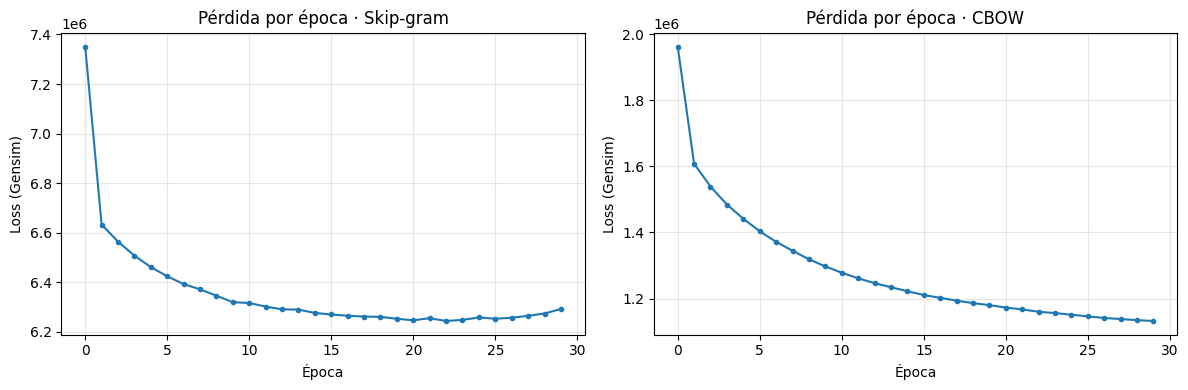

In [15]:
# Bloque 6 - Curvas de pérdida (código)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, logger, nombre in [(axes[0], logger_sg, "Skip-gram"), (axes[1], logger_cbow, "CBOW")]:
    ax.plot(range(len(logger.losses)), logger.losses, marker="o", markersize=3)
    ax.set_title(f"Pérdida por época · {nombre}")
    ax.set_xlabel("Época")
    ax.set_ylabel("Loss (Gensim)")
    ax.grid(alpha=0.3)
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/loss_corregida.png", dpi=150, bbox_inches="tight")
plt.show()

**Observaciones:**

- **Vocabulario:** el modelo se construyó sobre **38.879 documentos** y quedó con **8.624 palabras**,
  exactamente las que tenían frecuencia ≥ 5 en el análisis de la limpieza.
- **Tiempos:** Skip-gram tardó **≈ 220-240 s** y CBOW **60 s**, unas 4 veces menos. Es lo esperable:
  Skip-gram hace una predicción por cada palabra del contexto, mientras que CBOW hace una sola
  predicción por posición a partir del promedio del contexto.
- **Un error numérico en la pérdida de Gensim:** en una primera corrida, la pérdida del Skip-gram
  caía de 4,37 M a 0,35 M entre las épocas 13 y 14 y después quedaba plana. No era aprendizaje.
  Gensim acumula la pérdida en un `float32` (24 bits de mantisa), que pierde resolución cada vez
  que el acumulado cruza una potencia de 2 a partir de 2²⁴ ≈ 16,8 M. Desde ahí, los incrementos chicos
  se redondean y se pierden. Las caídas coincidían exactamente con esos cruces: en Skip-gram, en la
  época 6 (acumulado ≈ 33,2 M, cerca de 2²⁵) y en la época 13 (≈ 64,8 M, cerca de 2²⁶); en CBOW, en las
  épocas 6 (≈ 8,1 M, cerca de 2²³) y 15 (≈ 16,4 M, cerca de 2²⁴). Se corrigió reiniciando el acumulador
  al final de cada época en el callback. La corrección no afecta a los vectores, solo al valor
  reportado: la pérdida de la época 0, cuando el acumulado todavía no llegaba a 2²⁴, es idéntica en
  las dos corridas.

  ![Curvas con el error de precisión](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/loss_bug_float32.png)


- **Curvas corregidas:**

  ![Curvas de pérdida corregidas](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/loss_corregida.png)

  - **Skip-gram:** cae fuerte en la primera época (7,35 M → 6,63 M) y después desciende lento hasta
    un mínimo de ≈ 6,24 M en la época 22. Entre las épocas 15 y 22 la mejora ya es marginal (< 0,5%), y en
    las últimas épocas la pérdida sube levemente (6,29 M en la 29, +0,8% sobre el mínimo). Ese repunte
    no es sobreajuste: es una pérdida de entrenamiento con una estimación ruidosa, y en las
    últimas épocas la tasa de aprendizaje de Gensim ya es muy chica (decae linealmente hasta casi
    cero). El modelo **converge alrededor de la época 20**. Con 20 épocas se habría obtenido
    prácticamente el mismo resultado en un tercio menos de tiempo; se mantienen 30 porque no
    perjudican.
  - **CBOW:** la pérdida baja de forma monótona (1,96 M → 1,13 M) y en las últimas épocas todavía
    mejora ≈ 0,2-0,3% por época, así que **no terminó de estabilizarse**. Es esperable, porque CBOW
    hace menos actualizaciones por época que Skip-gram y necesita más pasadas. Más épocas le darían
    un ajuste algo mejor.
  - **Escalas no comparables:** la pérdida de Skip-gram es ≈ 5,5 veces mayor que la de CBOW porque
    suma un término por cada palabra del contexto (hasta 10 con `window=5`), mientras que CBOW suma uno
    por posición. Por eso se comparan las **tendencias**, no los valores. La calidad de los embeddings
    se evalúa en los pasos siguientes.

### 7 · Similitud entre términos

Se eligen 7 términos (la consigna pide al menos 5) que cubren distintos aspectos de la saga:

| Término | Por qué se eligió |
|---|---|
| `d'artagnan` | Protagonista y palabra de contenido más frecuente: ¿lo rodean sus compañeros o sus acciones? |
| `cardinal` | Es ambiguo dentro de la saga: designa a Richelieu en el primer libro y a Mazarino en el segundo. |
| `king` | Hay dos reyes (Luis XIII y Luis XIV): ¿qué contexto domina? |
| `sword` | Vocabulario militar y de duelo, central en una novela de capa y espada. |
| `pistoles` | La moneda de la época: Dumas habla mucho de dinero y deudas (como Porthos en la muestra del paso 4). |
| `love` | Vocabulario emocional, para contrastar con el de acción. |
| `bastille` | Lugar y prisión, clave en *The Man in the Iron Mask*. |

Para cada término se muestran las 10 palabras **más** similares (`positive`) y las 10 **menos**
similares (`negative`) en los dos modelos. Para **explicar** cada vecino con evidencia del corpus se
usa una función de contextos, que muestra en qué libros y en qué párrafos aparece la palabra.

**Sobre las menos similares:** `negative` devuelve las palabras cuyo vector apunta en la dirección
**opuesta** (similitud coseno más baja), no las "no relacionadas", que tendrían similitud cercana a 0.
Con valores cercanos a 0 o apenas negativos, el resultado indica más bien que no hay relación.

In [16]:
# Bloque 7 - Funciones de análisis (código)
import random
from IPython.display import display, Markdown

TERMINOS = ["d'artagnan", "cardinal", "king", "sword", "pistoles", "love", "bastille"]

# Control: todos los términos tienen que estar en el vocabulario
pd.DataFrame({
    "frecuencia": [frecuencias.get(t, 0) for t in TERMINOS],
    "en_vocabulario": [t in w2v_sg.wv for t in TERMINOS],
}, index=TERMINOS).T

,d'artagnan,cardinal,king,sword,pistoles,love,bastille
frecuencia,6169,1264,4895,555,214,814,31
en_vocabulario,True,True,True,True,True,True,True


In [17]:
def vecinos(modelo, palabra, topn=10, opuestos=False):
    clave = "negative" if opuestos else "positive"
    return [f"{w} ({s:.2f})" for w, s in modelo.wv.most_similar(**{clave: [palabra]}, topn=topn)]


def analizar(palabra, topn=10):
    """Tabla con las más y menos similares en Skip-gram y CBOW. No falla si la palabra no existe."""
    if palabra not in w2v_sg.wv:
        print(f"'{palabra}' no está en el vocabulario del modelo")
        return
    display(Markdown(f"#### `{palabra}` · frecuencia en el corpus: {frecuencias.get(palabra, 0):,}"))
    tabla = pd.DataFrame({
        ("Más similares", "Skip-gram"): vecinos(w2v_sg, palabra, topn),
        ("Más similares", "CBOW"): vecinos(w2v_cbow, palabra, topn),
        ("Menos similares", "Skip-gram"): vecinos(w2v_sg, palabra, topn, opuestos=True),
        ("Menos similares", "CBOW"): vecinos(w2v_cbow, palabra, topn, opuestos=True),
    }, index=range(1, topn + 1))
    display(tabla)


def contextos(palabra, n=5, largo=25):
    """Distribución por libro y algunos párrafos (ya tokenizados) donde aparece la palabra."""
    idx = [i for i, d in enumerate(documentos) if palabra in d]
    print(f"'{palabra}' aparece en {len(idx):,} documentos")
    print("Por libro:", dict(Counter(libro_de_doc[i] for i in idx).most_common()))
    for i in random.Random(SEED).sample(idx, min(n, len(idx))):
        print(f"  [{libro_de_doc[i]}] {' '.join(documentos[i][:largo])}")

In [18]:
# Bloque 7 - Un análisis por término
analizar("d'artagnan")

#### `d'artagnan` · frecuencia en el corpus: 6,169

Más similares                        Menos similares  \
            Skip-gram               CBOW           Skip-gram   
1        athos (0.79)      aramis (0.67)     contest (-0.02)   
2       aramis (0.77)   musketeer (0.63)     renders (-0.02)   
3      porthos (0.74)       athos (0.63)    surround (-0.02)   
4     planchet (0.68)     porthos (0.62)     princes (-0.03)   
5    musketeer (0.65)    planchet (0.56)     dowager (-0.03)   
6       gascon (0.62)  baisemeaux (0.50)      homage (-0.03)   
7   mousqueton (0.60)      gascon (0.49)  princesses (-0.03)   
8   baisemeaux (0.60)  mousqueton (0.49)    kingdoms (-0.04)   
9   invaluable (0.58)        host (0.45)     doctors (-0.04)   
10    treville (0.58)     groslow (0.45)  sovereigns (-0.05)   

                        
                  CBOW  
1   anticipated (0.42)  
2       gramont (0.41)  
3       dowager (0.41)  
4   negotiating (0.39)  
5        create (0.39)  
6     represent (0.39)  
7       embroil (0.39)  
8      compared (0.39)  
9    counteract (0.38)  
10     disposes (0.38)

In [19]:
analizar("cardinal")
contextos("cardinal")

#### `cardinal` · frecuencia en el corpus: 1,264

Más similares                     Menos similares                    
           Skip-gram              CBOW         Skip-gram                CBOW
1   richelieu (0.70)    mazarin (0.51)      river (0.07)     stripped (0.31)
2     mazarin (0.67)  richelieu (0.46)     embark (0.07)    separates (0.30)
3    eminence (0.61)   eminence (0.44)       leap (0.06)      meadows (0.30)
4    treville (0.56)   minister (0.42)  preserves (0.05)    inundated (0.30)
5    bernouin (0.56)   treville (0.41)      grows (0.05)       echoed (0.30)
6       queen (0.54)  comminges (0.39)    agility (0.04)  unceasingly (0.30)
7     regency (0.53)    colbert (0.38)     plains (0.03)   translated (0.29)
8      cavois (0.52)   chavigny (0.36)       bank (0.03)     distance (0.29)
9   circulate (0.51)   bernouin (0.36)    meadows (0.03)       saddle (0.28)
10  comminges (0.51)     police (0.36)  freshness (0.03)         hunt (0.28)

'cardinal' aparece en 1,118 documentos
Por libro: {'The Three Musketeers': 503, 'Twenty Years After': 353, 'The Vicomte de Bragelonne': 190, 'Ten Years Later': 31, 'Louise de la Valliere': 23, 'The Man in the Iron Mask': 18}
  [The Three Musketeers] yet journeyed along profound sadness weighed upon heart thought young pretty mme bonacieux paid price devotedness let us hasten say sadness possessed young man less
  [The Three Musketeers] cardinal majesty said really furious furious eight days absented king gaming table prevent king complacent possible whenever met asking kindest tone well monsieur cardinal fares
  [Twenty Years After] see cardinal replied queen enemies mine
  [The Three Musketeers] much better stop answered wounded man corbleu friend think first encounter could saying word cardinal throat cut
  [The Three Musketeers] listen happened brother coming assistance take away force necessary met emissary cardinal coming search followed solitary retired part road drew sword requi

In [20]:
analizar("king")

#### `king` · frecuencia en el corpus: 4,895

Más similares                       Menos similares  \
               Skip-gram               CBOW          Skip-gram   
1         majesty (0.69)     majesty (0.56)    weapons (-0.02)   
2           queen (0.65)  ambassador (0.45)   fountain (-0.04)   
3           louis (0.62)     holland (0.45)    feeding (-0.05)   
4           wales (0.61)    minister (0.45)      eaten (-0.05)   
5             xiv (0.61)         xiv (0.41)  faculties (-0.05)   
6          madame (0.60)       maria (0.40)  ambuscade (-0.05)   
7          cavois (0.59)       usher (0.40)      bones (-0.05)   
8          mother (0.59)    princess (0.39)     crusts (-0.05)   
9   granddaughter (0.59)       louis (0.39)      vault (-0.05)   
10       valliere (0.59)       queen (0.38)  resembled (-0.06)   

                       
                 CBOW  
1         hunt (0.44)  
2       steeds (0.40)  
3       honest (0.39)  
4   partridges (0.39)  
5      chicken (0.38)  
6       shrewd (0.36)  
7        roast (0.36)  
8     industry (0.36)  
9     cabarets (0.35)  
10       eaten (0.35)

In [21]:
analizar("sword")

#### `sword` · frecuencia en el corpus: 555

Más similares                      Menos similares                    
          Skip-gram             CBOW           Skip-gram                CBOW
1   scabbard (0.72)    pistol (0.57)    innocence (0.12)  preoccupied (0.40)
2       hilt (0.70)  scabbard (0.54)         amid (0.10)        nymph (0.39)
3     sheath (0.68)    rapier (0.52)     felicity (0.10)      deigned (0.38)
4      blade (0.64)   poniard (0.52)       verses (0.09)     dictated (0.37)
5     thrust (0.64)      hilt (0.51)    delicious (0.09)    composing (0.34)
6    pistols (0.59)    dagger (0.49)   singularly (0.09)     previous (0.34)
7      thigh (0.59)      whip (0.48)      reveals (0.09)    religious (0.33)
8     girded (0.58)   pistols (0.46)  flirtations (0.08)      scudery (0.32)
9     pistol (0.57)    weapon (0.46)      praised (0.08)       convey (0.32)
10     cloak (0.57)  holsters (0.46)    religious (0.08)    witnessed (0.32)

In [22]:
analizar("pistoles")

#### `pistoles` · frecuencia en el corpus: 214

Más similares                       Menos similares                    
          Skip-gram            CBOW             Skip-gram                CBOW
1    hundred (0.70)   livres (0.78)       combated (0.19)   throughout (0.37)
2     crowns (0.62)   pounds (0.76)        reigned (0.11)      reigned (0.36)
3        jew (0.62)   francs (0.74)       hilarity (0.10)       appeal (0.35)
4    trusses (0.62)   crowns (0.69)       floating (0.10)     terrible (0.34)
5      fifty (0.61)  trusses (0.64)        passers (0.09)    insulting (0.34)
6     eighty (0.61)    miles (0.60)          limit (0.09)    prevailed (0.34)
7     francs (0.61)    franc (0.54)    constituted (0.09)      passion (0.34)
8     livres (0.60)   ninety (0.54)      prevailed (0.09)     accosted (0.33)
9    pistole (0.59)  leagues (0.53)        attacks (0.09)  approbation (0.33)
10  thousand (0.59)    purse (0.53)  preoccupation (0.09)     realized (0.33)

In [23]:
analizar("love")

#### `love` · frecuencia en el corpus: 814

Más similares                       Menos similares                  
             Skip-gram               CBOW          Skip-gram              CBOW
1         loved (0.68)       loves (0.64)        shop (0.13)   quarters (0.53)
2         loves (0.60)       loved (0.63)    quarters (0.11)    stables (0.49)
3         madly (0.60)      loving (0.57)     patrols (0.09)   escorted (0.47)
4     devotedly (0.58)   affection (0.54)       doors (0.09)     thence (0.45)
5     affection (0.58)       madly (0.53)       hedge (0.09)  sentinels (0.44)
6    confessing (0.56)  infidelity (0.50)      colors (0.08)   preceded (0.44)
7       defiled (0.56)       cruel (0.50)  barricades (0.08)     eveque (0.42)
8     intercede (0.55)     beloved (0.48)       faced (0.08)    saddled (0.41)
9         lover (0.55)    sympathy (0.48)     stables (0.08)      posts (0.41)
10  distraction (0.55)       rival (0.47)        wand (0.07)   governor (0.40)

In [24]:
analizar("bastille")

#### `bastille` · frecuencia en el corpus: 31

Más similares                         Menos similares  \
            Skip-gram              CBOW             Skip-gram   
1     montague (0.54)   montague (0.53)       instinct (0.24)   
2   prohibited (0.52)      greve (0.45)         fibers (0.20)   
3       eveque (0.51)    bearers (0.41)            fed (0.12)   
4        gaily (0.50)     hiding (0.41)      developed (0.12)   
5      penalty (0.50)   baudoyer (0.41)    recommended (0.11)   
6      terrify (0.50)     papers (0.40)  magnificently (0.11)   
7      bastile (0.48)    grating (0.39)    intoxicated (0.11)   
8       pierre (0.46)    penalty (0.39)      enjoyment (0.11)   
9     gratings (0.46)     drawer (0.38)         taught (0.11)   
10      prison (0.46)  yesterday (0.38)         health (0.11)   

                       
                 CBOW  
1       tender (0.40)  
2    overwhelm (0.38)  
3   passionate (0.37)  
4      manners (0.36)  
5     courtier (0.36)  
6       gentle (0.35)  
7    insulting (0.34)  
8         rash (0.33)  
9      careful (0.33)  
10   gratified (0.32)

**Palabras fuera del vocabulario:** Word2Vec solo tiene vectores para las palabras vistas en el
entrenamiento con al menos `min_count` apariciones. Consultar una palabra que no está produce un
`KeyError`, así que se captura la excepción para que el notebook corra sin errores. Se prueba con
una palabra ajena a la saga (*harry*) y con la forma rota del protagonista (*dartagnan*). FastText
resolvería este caso armando el vector a partir de n-gramas de caracteres.

In [25]:
for palabra in ["harry", "dartagnan"]:
    try:
        w2v_sg.wv.most_similar(positive=[palabra], topn=5)
    except KeyError as e:
        print(f"KeyError → {e}")

KeyError → "Key 'harry' not present in vocabulary"
KeyError → "Key 'dartagnan' not present in vocabulary"


**Observaciones generales sobre los dos modelos:**

- **Skip-gram encuentra relaciones de co-ocurrencia; CBOW, de sustitución.** Skip-gram tiende a
  devolver palabras que **aparecen junto** al término (*sword* → *scabbard*, *hilt*, *sheath*: "sacó la
  espada de la vaina"). CBOW devuelve palabras que **podrían ocupar su lugar** en la oración (*sword* →
  *pistol*, *rapier*, *poniard*, *dagger*: otras armas). Las dos son formas de "similitud", pero responden
  a preguntas distintas: Skip-gram, ¿de qué se habla junto a esta palabra?; CBOW, ¿qué otra palabra
  cumple el mismo rol?
- **Las "menos similares" no significan lo mismo en los dos modelos.** En Skip-gram tienen similitud
  cercana a 0 (entre −0,06 y 0,24), es decir, **sin relación**, como se anticipó. En CBOW, en cambio,
  incluso las menos similares tienen similitudes **positivas** de 0,3 a 0,5. Eso indica que el espacio
  de CBOW es **anisotrópico**: todos sus vectores comparten una dirección común, probablemente asociada
  a la frecuencia, y quedan concentrados en un cono. Por eso, en CBOW conviene leer las menos similares
  como un orden relativo y no como "opuestas".
- **Las menos similares revelan los dos mundos de la novela.** En casi todos los términos, lo opuesto
  separa el registro de **acción y vida militar** (cuarteles, establos, patrullas, armas, comida de
  taberna) del registro de **corte, diplomacia y salón** (príncipes, soberanos, homenajes, versos,
  galanteos). Es una estructura real de la obra de Dumas, que alterna entre ambos ambientes.

**`d'artagnan`:** los vecinos más cercanos en ambos modelos son **sus tres compañeros** (*athos*,
*aramis*, *porthos*, con similitudes de 0,74 a 0,79 en Skip-gram), su lacayo **planchet**, su rango
(*musketeer*) y su origen (**gascon**). Aparecen también personajes de distintas épocas: *treville*
(su capitán en el primer libro), *mousqueton* (lacayo de Porthos), *baisemeaux* (gobernador de la
Bastilla en *Bragelonne*) y, en CBOW, *groslow* (*Twenty Years After*). Eso muestra que el vector integra
la saga completa. *invaluable* es ruido. Las menos similares son vocabulario de **alta política y
realeza** (*princes*, *princesses*, *sovereigns*, *kingdoms*, *homage*, *dowager*; en CBOW, *negotiating*,
*represent*), y la coincidencia entre ambos modelos sugiere que es una señal real: d'Artagnan es un
hombre de acción, ajeno al discurso diplomático.

**`cardinal`:** se confirma lo anticipado en la limpieza: el vector **mezcla a los dos cardenales**.
En Skip-gram, *richelieu* (0,70) y *mazarin* (0,67) quedan casi empatados, y CBOW invierte el orden. La
distribución por libro lo explica: *cardinal* aparece en 503 documentos de *The Three Musketeers*
(Richelieu) y en 353 de *Twenty Years After* (Mazarino), y casi desaparece después. El resto de los vecinos
forma el **entorno de ambos cardenales**: el tratamiento *eminence*, el cargo *minister*, *bernouin*
(ayuda de cámara de Mazarino), *cavois* (capitán de la guardia de Richelieu), *comminges*, la *regency* y la
*queen* (Ana de Austria, aliada de Mazarino), y **colbert** en CBOW (intendente de Mazarino y luego su
sucesor). *treville* aparece como **rival**: los mosqueteros del rey contra los guardias del cardenal.
Las menos similares son paisaje y vida al aire libre (*river*, *meadows*, *plains*, *bank*): el cardenal
pertenece al mundo del palacio. **Limitación:** Word2Vec asigna un único vector por palabra, así que un
término que designa a dos personas distintas queda en un punto intermedio entre ambas.

**`king`:** el vecino más cercano es su tratamiento, *majesty*, en los dos modelos. Lo interesante es
**qué rey** domina: *xiv*, *valliere* (amante de Luis XIV), *madame* (Enriqueta, su cuñada) y *mother* (la reina
madre) son todos de la etapa de *Bragelonne*. El vector se inclina hacia **Luis XIV** y no hacia Luis XIII,
coherente con que los últimos cuatro libros, centrados en su corte, suman más texto. *wales* (el príncipe de
Gales, luego Carlos II) refleja la subtrama inglesa. CBOW agrega vocabulario **diplomático** (*ambassador*,
*holland*, *minister*, *maria* por María Teresa). Las menos similares son **comida y vida de soldado**
(*eaten*, *bones*, *crusts*, *weapons*, *ambuscade*; en CBOW *roast*, *partridges*, *chicken*, *cabarets*):
el rey nunca está en las escenas de taberna ni de emboscada.

**`sword`:** es el ejemplo más claro de la diferencia entre modelos. Skip-gram devuelve las **partes y
acciones** de la espada (*scabbard*, *hilt*, *sheath*, *blade*, *thrust*, *girded*, *thigh*), y hasta
*cloak*: la novela es literalmente **de capa y espada**. CBOW devuelve **otras armas** que ocupan el mismo
lugar en la oración (*pistol*, *rapier*, *poniard*, *dagger*, *whip*, *weapon*, *holsters*). Las menos
similares son el **registro galante y poético**: *innocence*, *felicity*, *verses*, *flirtations*,
*praised* y, en CBOW, *scudery* (Madeleine de Scudéry, figura de los salones literarios), justo el mundo
opuesto al duelo.

**`pistoles`:** el modelo aprendió la categoría de **dinero y cantidades**. Skip-gram la rodea de
**números** (*hundred*, *fifty*, *eighty*, *thousand*), porque en el texto casi siempre se cuenta ("cien
pistolas"). CBOW la rodea de **otras monedas** (*livres*, *pounds*, *francs*, *crowns*) y, curiosamente, de
**unidades de distancia** (*miles*, *leagues*): CBOW agrupa lo que ocupa el lugar "número + unidad", sin
distinguir si la unidad es dinero o longitud. La aparición de *pistole* (singular) muestra que no
lematizar no impidió vincular singular y plural.
Dos vecinos se explican volviendo al texto:
- **`trusses`** aparece en solo **5 documentos**, todos de un mismo episodio de *Twenty Years After*:
  d'Artagnan y Mousqueton compran y revenden fardos de paja (*trusses of straw*) para dormir, siempre
  con su precio en pistolas o luises. Es un caso de **sobreajuste a un pasaje puntual**, como los
  estribillos del ejemplo de los Beatles.
- **`jew`** aparece en solo **7 documentos**, y en ellos se ve un **sesgo** del corpus. En dos casos la
  palabra está asociada a vender un diamante o un anillo al mejor precio en pistolas (*The Three
  Musketeers*, *Bragelonne*), reproduciendo el estereotipo de la época que vincula a los judíos con el
  dinero. En otro aparece como insulto. Con muy pocas apariciones, la asociación queda grabada en el
  vector: los embeddings **heredan los sesgos del texto** con el que se entrenan, una limitación
  importante de estos modelos.

In [26]:
# Origen de dos vecinos de "pistoles" que no se explican solos
contextos("trusses", n=3)
contextos("jew", n=3)

'trusses' aparece en 5 documentos
Por libro: {'Twenty Years After': 5}
  [Twenty Years After] d'artagnan went instantly hay dealer bargained hundred fifty trusses straw obtained rate three pistoles went afterward innkeeper bought two hundred trusses price finally farmer louis
  [Twenty Years After] porthos however found straw left returned mousqueton steward sold last wisp repaired d'artagnan thanks four trusses straw act making tasting anticipation luxury bed soft well
  [Twenty Years After] conducted mousqueton freely distributed trusses rate louis apiece thought rather dear people wanted sleep would give even two three louis hours sound sleep
'jew' aparece en 7 documentos
Por libro: {'The Three Musketeers': 4, 'Twenty Years After': 2, 'The Vicomte de Bragelonne': 1}
  [Twenty Years After] continued walk scarcely gone hundred paces furious fellow leaning two soldiers spat king face infamous accursed jew spit face jesus nazareth loud roars laughter sullen
  [The Three Musketeers] well

**`love`:** los vecinos más cercanos son sus **flexiones** (*loved*, *loves*, *loving*), los adverbios
con que Dumas lo acompaña (*madly*, *devotedly*) y el campo afectivo (*affection*, *lover*, *beloved*,
*sympathy*). CBOW agrega el lado conflictivo del amor en la novela (*infidelity*, *rival*, *cruel*). Las
menos similares son la **logística militar** (*quarters*, *stables*, *patrols*, *barricades*, *sentinels*,
*posts*, *saddled*): la oposición más nítida de las siete entre los dos mundos de la obra.

**`bastille` / `bastile`:** con solo **31 apariciones**, los vecinos de *bastille* mezclaban sentido
(*prison*, *gratings*, *penalty*) con ruido sin explicación (*gaily*, *terrify*, *yesterday*). La clave
estaba en uno de sus vecinos: esta traducción escribe la palabra mayormente con una sola *l*,
**bastile**, que aparece **188 veces**. Analizando esa grafía, los vecinos se vuelven coherentes:
- **El mundo carcelario:** *prison*, *jailer*, *prisoner(s)*, *turnkeys*, *release*.
- **Su gobernador:** *governor*, *baisemeaux* y **montlezun**. Baisemeaux de Montlezun es el nombre
  completo del gobernador, así que el modelo vinculó las dos mitades del nombre.
- **Otras prisiones de Estado:** *vincennes* (de donde se fuga el duque de Beaufort en *Twenty Years
  After*) y *rueil*.

Las menos similares vuelven a ser el registro galante (*beauty*, *coquette*, *flower*, *kissed*,
*passionately*). La distribución por libro confirma que la Bastilla gana peso al final de la saga
(57 documentos en *The Man in the Iron Mask*).

**Lecciones:** (1) la **frecuencia** determina la calidad del vector: la misma palabra pasa de vecinos
ruidosos con 31 apariciones a vecinos precisos con 188. (2) Las **variantes ortográficas** dividen la
frecuencia de una palabra en dos tokens. Una mejora posible del preprocesamiento sería unificarlas
(*bastille* → *bastile*); no se aplicó para no reentrenar, pero queda documentado como limitación.

In [27]:
# ¿Cómo se escribe "Bastilla" en esta traducción?
for w in ["bastille", "bastile"]:
    print(f"{w:<10} frecuencia: {frecuencias.get(w, 0):>4}")

analizar("bastile")
contextos("bastile", n=3)

bastille   frecuencia:   31
bastile    frecuencia:  188


#### `bastile` · frecuencia en el corpus: 188

Más similares                       Menos similares  \
            Skip-gram               CBOW          Skip-gram   
1       prison (0.63)      prison (0.61)   displayed (0.12)   
2    montlezun (0.62)      jailer (0.50)  confounded (0.11)   
3     governor (0.54)   vincennes (0.48)    applause (0.09)   
4     prisoner (0.53)    turnkeys (0.46)      beauty (0.09)   
5    vincennes (0.52)   prisoners (0.45)     touched (0.08)   
6     turnkeys (0.52)       rueil (0.44)    coquette (0.08)   
7    prisoners (0.51)   montlezun (0.44)      flower (0.08)   
8      seguier (0.50)  baisemeaux (0.43)     genuine (0.08)   
9      release (0.50)    prisoner (0.43)        wide (0.07)   
10  baisemeaux (0.49)    governor (0.42)       blind (0.07)   

                         
                   CBOW  
1      caressing (0.41)  
2         tender (0.41)  
3        clasped (0.41)  
4        nervous (0.40)  
5      displayed (0.39)  
6       coquette (0.36)  
7         kissed (0.36)  
8        admired (0.36)  
9         bitter (0.36)  
10  passionately (0.35)

'bastile' aparece en 170 documentos
Por libro: {'The Man in the Iron Mask': 57, 'Louise de la Valliere': 40, 'Twenty Years After': 32, 'Ten Years Later': 31, 'The Vicomte de Bragelonne': 10}
  [The Man in the Iron Mask] yes wish see prison bastile instance
  [Twenty Years After] friend said aramis take care safety lies obscurity make known sent rejoin friends deep ditch devil could take us let us try find accident notions
  [Twenty Years After] drunk yet since amusement seemed rather tame proposed chevalier rieux spectators instead actors order see advantage mount bronze horse sooner said done thanks spurs served


**Fuera del vocabulario:** *harry* (ajena al corpus) y *dartagnan* (la forma rota que la limpieza
evitó crear) dan `KeyError`, capturado con `try/except` para que el notebook corra completo.

### 8 · Analogías

La slide del desafío propone probar analogías con aritmética de vectores: *a es a b como c es a ?*
se resuelve buscando la palabra más cercana a **b − a + c**. En Gensim se hace con `most_similar`
combinando `positive=[b, c]` y `negative=[a]`, y las palabras de entrada se excluyen del resultado.

En lugar de usar solo el ejemplo clásico, se plantean analogías **con respuesta conocida dentro de
la saga**, para poder evaluarlas:

| Relación | Analogía | Respuesta esperada |
|---|---|---|
| Género | man : king :: woman : ? | queen |
| Amo y lacayo | d'artagnan : planchet :: athos : ? | grimaud |
| Amo y lacayo | d'artagnan : planchet :: porthos : ? | mousqueton |
| Amo y lacayo | d'artagnan : planchet :: aramis : ? | bazin |
| Singular y plural | pistole : pistoles :: crown : ? | crowns |

In [28]:
def analogia(a, b, c, esperado=None, topn=5):
    """a es a b como c es a ?   →   b − a + c"""
    faltan = [w for w in (a, b, c, esperado) if w and w not in w2v_sg.wv]
    if faltan:
        print(f"Fuera del vocabulario: {faltan}")
        return
    print(f"{a} : {b} :: {c} : ?   (esperado: {esperado})")
    for nombre, modelo in [("Skip-gram", w2v_sg), ("CBOW", w2v_cbow)]:
        res = modelo.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
        palabras = [w for w, _ in res]
        if esperado in palabras:
            veredicto = f"✔ posición {palabras.index(esperado) + 1}"
        else:
            veredicto = f"✘ no está en el top {topn}"
        print(f"  {nombre:<10} " + ", ".join(f"{w} ({s:.2f})" for w, s in res) + f"   {veredicto}")
    print()


ANALOGIAS = [
    ("man", "king", "woman", "queen"),
    ("d'artagnan", "planchet", "athos", "grimaud"),
    ("d'artagnan", "planchet", "porthos", "mousqueton"),
    ("d'artagnan", "planchet", "aramis", "bazin"),
    ("pistole", "pistoles", "crown", "crowns"),
]
for a, b, c, esperado in ANALOGIAS:
    analogia(a, b, c, esperado)

man : king :: woman : ?   (esperado: queen)
  Skip-gram  queen (0.59), maria (0.57), theresa (0.55), majesty (0.53), granddaughter (0.51)   ✔ posición 1
  CBOW       maria (0.57), theresa (0.56), mother (0.46), henrietta (0.44), charente (0.43)   ✘ no está en el top 5

d'artagnan : planchet :: athos : ?   (esperado: grimaud)
  Skip-gram  grocer (0.57), grimaud (0.55), mousqueton (0.54), porthos (0.52), blaisois (0.50)   ✔ posición 2
  CBOW       mousqueton (0.50), blaisois (0.45), porthos (0.44), grimaud (0.39), grocer (0.38)   ✔ posición 4

d'artagnan : planchet :: porthos : ?   (esperado: mousqueton)
  Skip-gram  mousqueton (0.58), grocer (0.52), truchen (0.49), samson (0.48), blaisois (0.47)   ✔ posición 1
  CBOW       mousqueton (0.53), blaisois (0.51), grocer (0.43), moliere (0.42), partner (0.40)   ✔ posición 1

d'artagnan : planchet :: aramis : ?   (esperado: bazin)
  Skip-gram  athos (0.51), porthos (0.51), grimaud (0.51), mousqueton (0.50), pilon (0.49)   ✘ no está en el top 5

**Observaciones:**

| Analogía | Skip-gram | CBOW |
|---|---|---|
| man : king :: woman : **queen** | ✔ 1.º | ✘ |
| d'artagnan : planchet :: athos : **grimaud** | ✔ 2.º | ✔ 4.º |
| d'artagnan : planchet :: porthos : **mousqueton** | ✔ 1.º | ✔ 1.º |
| d'artagnan : planchet :: aramis : **bazin** | ✘ | ✔ 3.º |
| pistole : pistoles :: crown : **crowns** | ✘ | ✔ 2.º |

- **Género (man → woman):** Skip-gram resuelve la analogía clásica con *queen* en primer lugar, seguida
  de *maria* y *theresa* (María Teresa, la reina de Luis XIV): la respuesta es correcta y además propia
  del corpus. CBOW no pone *queen* en el top 5, pero todas sus respuestas son **mujeres de la realeza**
  (*maria*, *theresa*, *mother*, *henrietta*): captura la categoría, aunque no la palabra exacta,
  coherente con su tendencia a devolver términos que pueden sustituirse entre sí.
- **Amo y lacayo:** el modelo aprendió la **categoría "lacayo"**, porque casi todas las respuestas son
  sirvientes (*mousqueton*, *grimaud*, *bazin*, *blaisois*, el lacayo de Raoul). Pero el **emparejamiento
  específico** solo sale bien cuando el par aparece mucho junto: *porthos → mousqueton* acierta en primer
  lugar en ambos modelos, mientras que *aramis → bazin* falla en Skip-gram. Aparece además un error
  típico de las analogías: **grocer** encabeza los resultados para Athos porque Planchet se vuelve
  almacenero en *Bragelonne*. El vector **b − a + c** conserva atributos propios de *b* (Planchet) que no
  forman parte de la relación buscada.
- **Singular y plural:** Skip-gram falla y devuelve vocabulario **temático** de montos de dinero
  (*hundred*, *weighs*, *amounted*, y *emery*, por Particelli d'Émery, el superintendente de finanzas de
  Mazarino). CBOW acierta con *crowns* en segundo lugar, detrás de otras monedas.
- **Balance:** Skip-gram acierta 3 de 5 y CBOW 4 de 5 dentro del top 5. Skip-gram rinde mejor en la
  relación **semántica** (género) y CBOW en las relaciones **morfológicas y de categoría** (plural, lacayos),
  lo que coincide con lo observado en los vecinos: Skip-gram captura co-ocurrencia temática y CBOW,
  sustitución.

### 9 · Reducción de dimensionalidad y visualización

Se proyectan los vectores de 100 dimensiones del modelo **Skip-gram** (el principal) a 2D con
**t-SNE**, usando la misma función de clase con semilla fija. t-SNE se calcula **una sola vez sobre todo
el vocabulario** y después se eligen qué palabras dibujar.

**Cómo leer t-SNE:** conserva bien las **vecindades locales** (palabras cercanas en 100D quedan cerca en
2D), pero las distancias entre grupos alejados y el tamaño de los grupos **no tienen significado**. Por
eso se interpretan los grupos pequeños y no la posición global.

**Elección de `MAX_WORDS`:** el vocabulario está ordenado por frecuencia, así que `MAX_WORDS` dibuja
las N palabras más frecuentes. Se prueban 75, 150 y 300 para elegir la cantidad que deja el gráfico legible.

Los gráficos estáticos se generan con matplotlib y se guardan en `images/`. Así las capturas
quedan reproducibles: no dependen del renderizado de Plotly, que no se ve en GitHub. Además se
incluye una versión interactiva con Plotly para explorar.

In [29]:
# Bloque 9 - t-SNE
from sklearn.manifold import TSNE
import plotly.express as px

def reduce_dimensions(model, num_dimensions=2, seed=SEED):
    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)
    tsne = TSNE(n_components=num_dimensions, random_state=seed)
    return tsne.fit_transform(vectors), labels

t0 = time.time()
vecs_2d, labels = reduce_dimensions(w2v_sg, 2)
print(f"t-SNE sobre {len(labels):,} palabras: {time.time() - t0:.0f} s")

df_2d = pd.DataFrame({
    "x": vecs_2d[:, 0],
    "y": vecs_2d[:, 1],
    "palabra": labels,
    "frecuencia": [w2v_sg.wv.get_vecattr(w, "count") for w in labels],
})
os.makedirs("images", exist_ok=True)

t-SNE sobre 8,624 palabras: 139 s


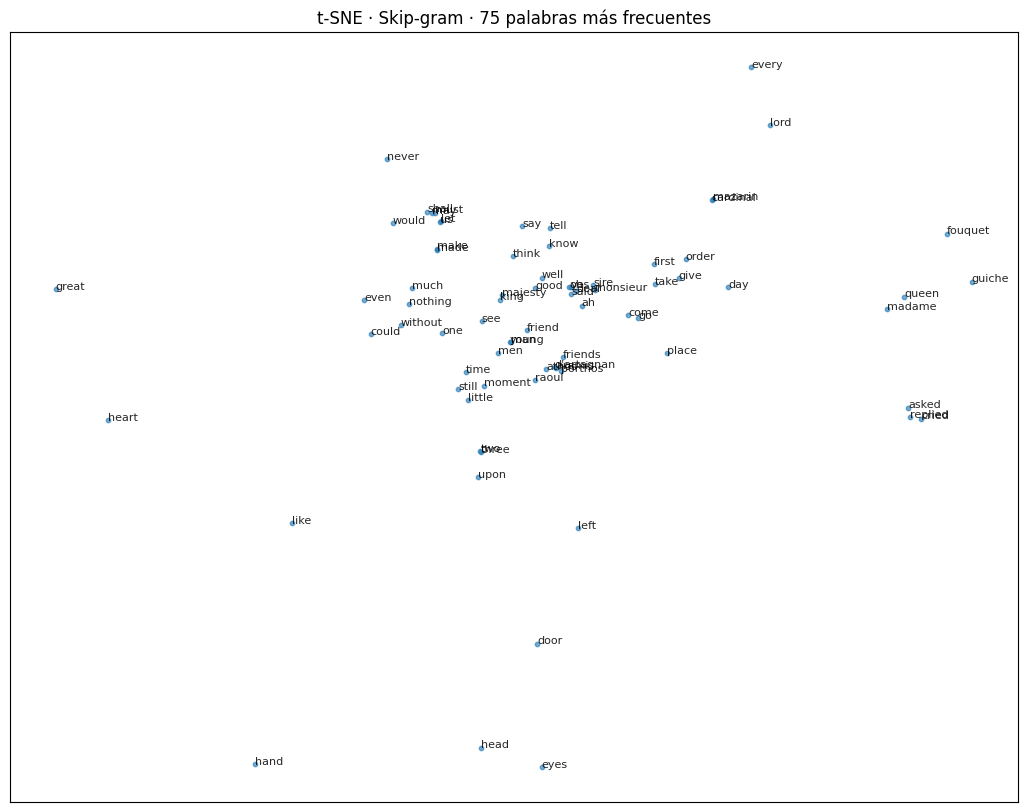

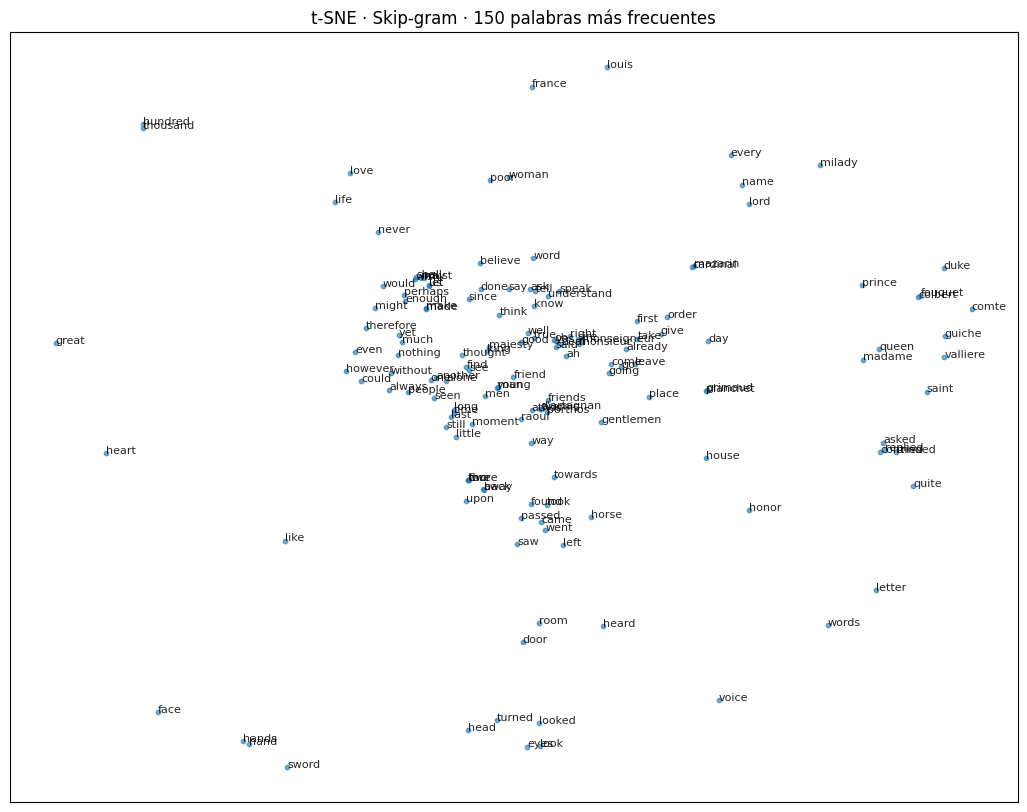

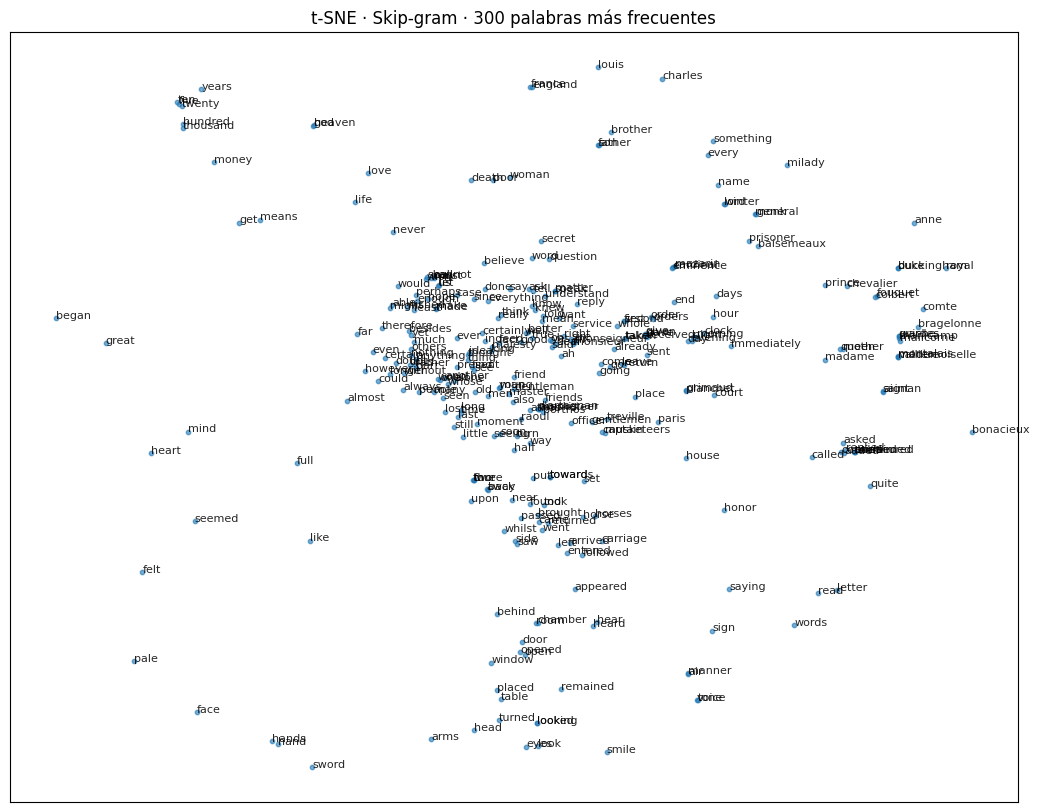

In [30]:
# Bloque 9 - Elección de MAX_WORDS
def graficar_top(max_words, guardar=True):
    sub = df_2d.head(max_words)
    fig, ax = plt.subplots(figsize=(13, 10))
    ax.scatter(sub.x, sub.y, s=10, alpha=0.6)
    for _, r in sub.iterrows():
        ax.annotate(r.palabra, (r.x, r.y), fontsize=8, alpha=0.85)
    ax.set_title(f"t-SNE · Skip-gram · {max_words} palabras más frecuentes")
    ax.set_xticks([]); ax.set_yticks([])
    if guardar:
        plt.savefig(f"images/tsne_top{max_words}.png", dpi=150, bbox_inches="tight")
    plt.show()

for n in [75, 150, 300]:
    graficar_top(n)

In [31]:
# Versión interactiva para explorar (zoom y hover)
MAX_WORDS = 150   # ajustar según lo que se vea en los gráficos anteriores
fig = px.scatter(df_2d.head(MAX_WORDS), x="x", y="y", text="palabra", hover_data=["frecuencia"],
                 title=f"t-SNE · Skip-gram · {MAX_WORDS} palabras más frecuentes")
fig.update_traces(textposition="top center", marker=dict(size=4))
fig.update_layout(height=800)
fig.show(renderer="colab")

Fuera del vocabulario (se omiten): []


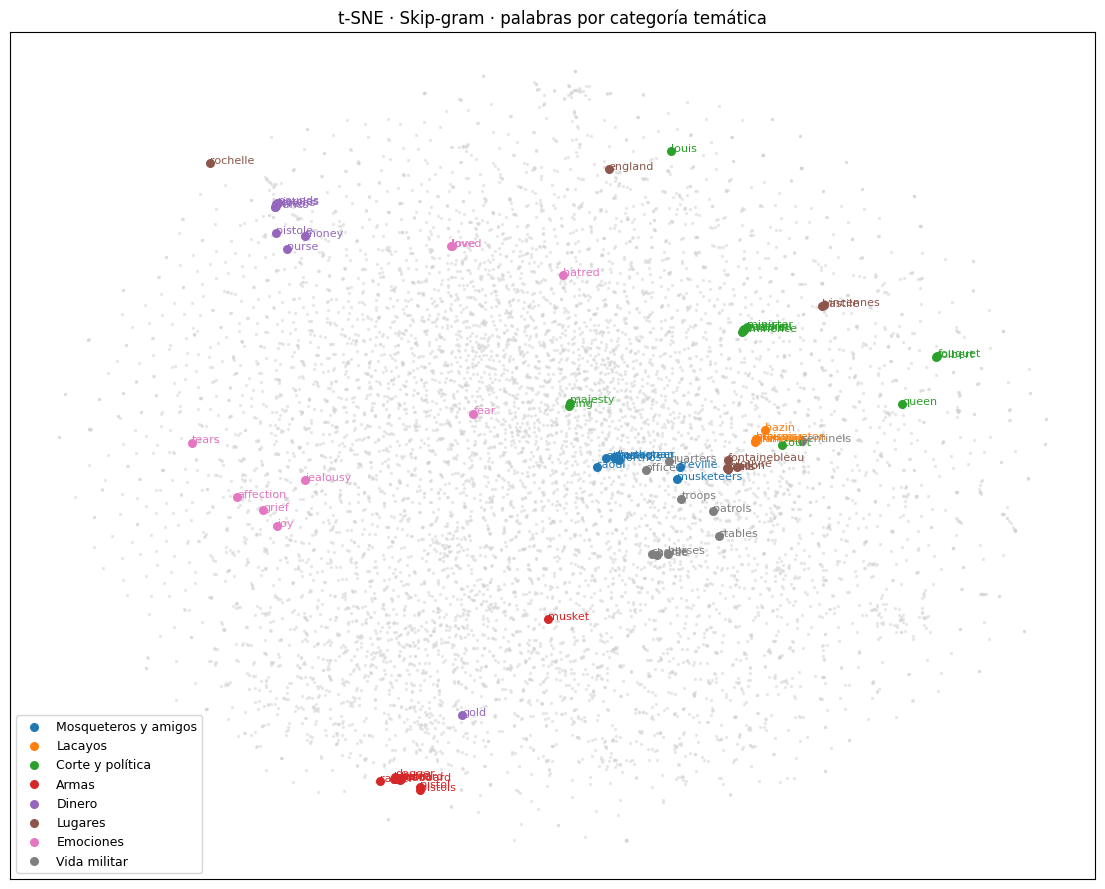

In [32]:
# Bloque 9 - Mapa por categorías temáticas
CATEGORIAS = {
    "Mosqueteros y amigos": ["d'artagnan", "athos", "porthos", "aramis", "raoul", "treville", "musketeer", "musketeers"],
    "Lacayos": ["planchet", "grimaud", "mousqueton", "bazin", "blaisois"],
    "Corte y política": ["king", "queen", "cardinal", "richelieu", "mazarin", "fouquet", "colbert",
                         "louis", "majesty", "eminence", "minister", "court"],
    "Armas": ["sword", "scabbard", "hilt", "blade", "pistol", "pistols", "rapier", "poniard", "dagger", "musket"],
    "Dinero": ["pistoles", "pistole", "crowns", "livres", "francs", "pounds", "purse", "gold", "money"],
    "Lugares": ["paris", "london", "bastile", "vincennes", "louvre", "rochelle", "blois", "fontainebleau", "england"],
    "Emociones": ["love", "loved", "affection", "hatred", "jealousy", "tears", "joy", "fear", "grief"],
    "Vida militar": ["quarters", "stables", "sentinels", "patrols", "horse", "horses", "saddle", "troops", "officer"],
}

faltan = [w for ws in CATEGORIAS.values() for w in ws if w not in w2v_sg.wv]
print("Fuera del vocabulario (se omiten):", faltan)

fig, ax = plt.subplots(figsize=(14, 11))
ax.scatter(df_2d.x, df_2d.y, s=2, color="lightgray", alpha=0.4)   # todo el vocabulario de fondo
pos = df_2d.set_index("palabra")
for (cat, palabras), color in zip(CATEGORIAS.items(), plt.cm.tab10.colors):
    palabras = [w for w in palabras if w in pos.index]
    ax.scatter(pos.loc[palabras, "x"], pos.loc[palabras, "y"], s=30, color=color, label=cat)
    for w in palabras:
        ax.annotate(w, (pos.loc[w, "x"], pos.loc[w, "y"]), fontsize=8, color=color)
ax.legend(loc="best", fontsize=9)
ax.set_title("t-SNE · Skip-gram · palabras por categoría temática")
ax.set_xticks([]); ax.set_yticks([])
plt.savefig("images/tsne_categorias.png", dpi=150, bbox_inches="tight")
plt.show()

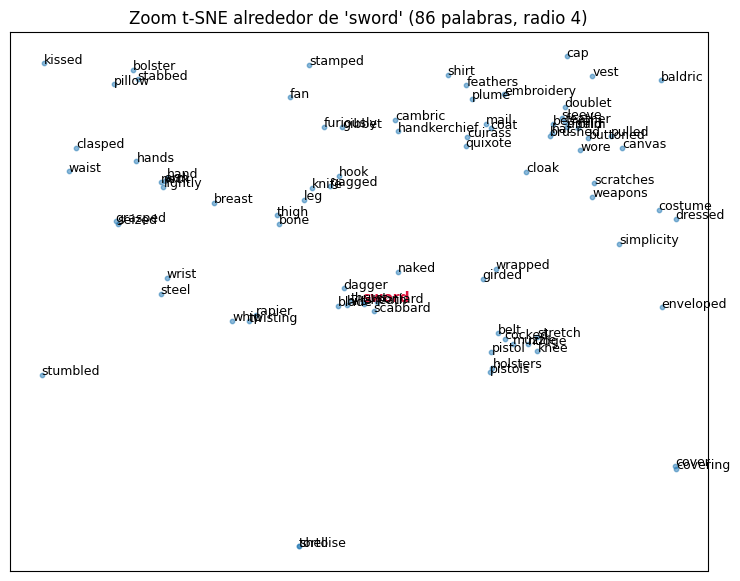

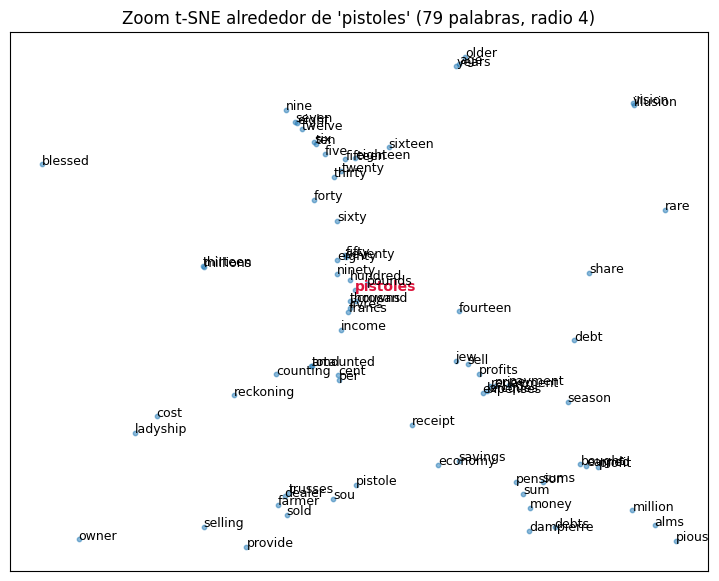

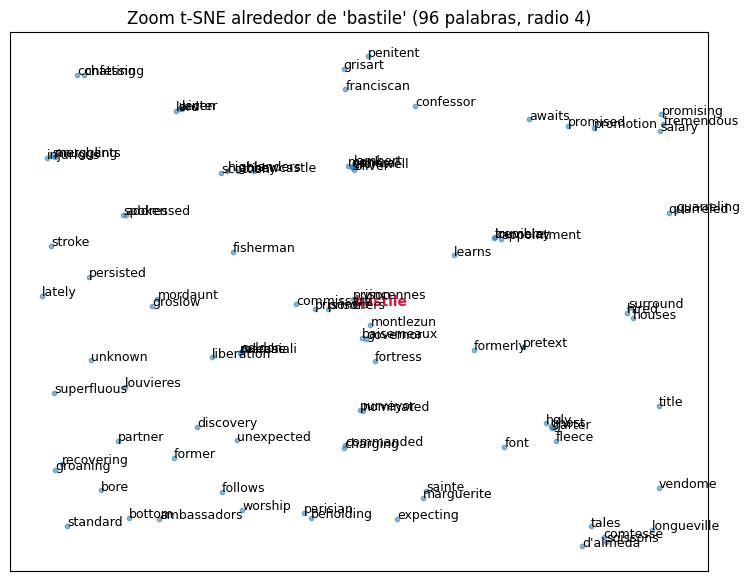

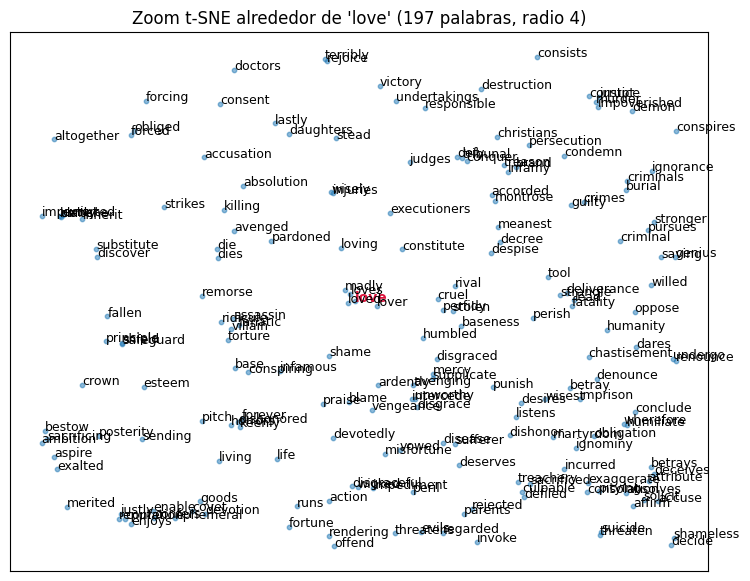

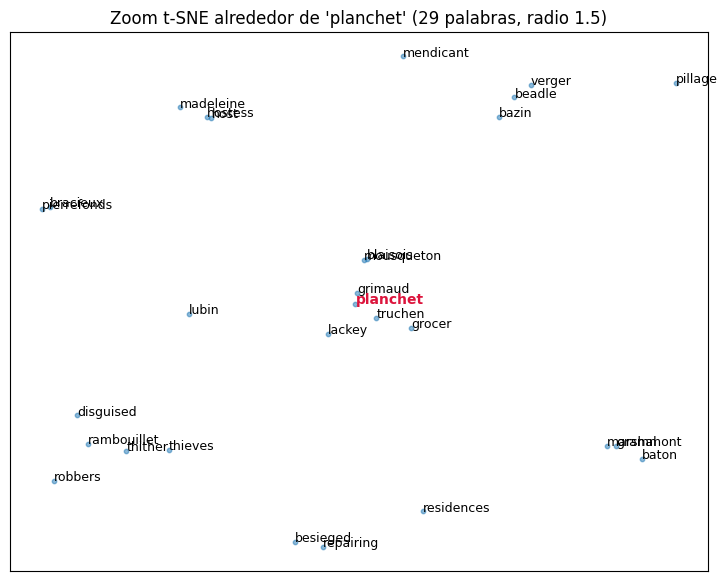

In [33]:
# Bloque 9 - Zoom sobre grupos
def zoom(palabra, radio=4, guardar=True):
    """Dibuja todas las palabras del vocabulario cercanas a `palabra` en el plano t-SNE."""
    if palabra not in pos.index:
        print(f"'{palabra}' no está en el vocabulario")
        return
    cx, cy = pos.loc[palabra, ["x", "y"]]
    sub = df_2d[(abs(df_2d.x - cx) < radio) & (abs(df_2d.y - cy) < radio)]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.scatter(sub.x, sub.y, s=10, alpha=0.5)
    for _, r in sub.iterrows():
        es_centro = r.palabra == palabra
        ax.annotate(r.palabra, (r.x, r.y), fontsize=10 if es_centro else 9,
                    fontweight="bold" if es_centro else "normal",
                    color="crimson" if es_centro else "black")
    ax.set_title(f"Zoom t-SNE alrededor de '{palabra}' ({len(sub)} palabras, radio {radio})")
    ax.set_xticks([]); ax.set_yticks([])
    if guardar:
        nombre = re.sub(r"\W", "_", palabra)
        plt.savefig(f"images/cluster_{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


# Zooms de los 5 clusters (planchet con radio menor porque cae en una zona densa del mapa)
ZOOMS = [("sword", 4), ("pistoles", 4), ("bastile", 4), ("love", 4), ("planchet", 1.5)]
for w, r in ZOOMS:
    zoom(w, radio=r)

**Elección de `MAX_WORDS`:** t-SNE sobre las 8.624 palabras tardó entre 2 y 4 minutos según la corrida.

| 75 | 150 | 300 |
|---|---|---|
| ![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/tsne_top75.png) | ![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/tsne_top150.png) | ![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/tsne_top300.png) |

- **75 palabras:** todo es legible, pero se ven pocas estructuras: los cardenales superpuestos
  (*mazarin* / *cardinal*), *queen* junto a *madame*, los verbos de diálogo y algunos números.
- **150 palabras:** sigue siendo legible y aparecen grupos claros en la periferia. Es el valor elegido.
- **300 palabras:** el centro se satura y las etiquetas se superponen, aunque en los bordes aparecen
  grupos nuevos (*years*, *twenty*, *ten*; *bragelonne*, *vicomte*, *mademoiselle*; *door*, *opened*,
  *window*, *chamber*).

**Lectura del mapa con 150 palabras:**
- **El centro denso** concentra las palabras más generales (*would*, *might*, *perhaps*, *nothing*,
  *think*, *know*): aparecen con todo tipo de vocabulario y no tienen un contexto propio.
- **Los grupos de la periferia** son temáticos:
  - **Verbos de diálogo:** *asked*, *replied*, *cried*, *continued*, la marca del estilo de Dumas.
  - **La corte de Luis XIV:** *fouquet*, *colbert*, *guiche*, *valliere*, *comte*, *duke*, *prince*.
  - **Cantidades:** *hundred*, *thousand*.
  - **Cuerpo y gesto:** *head*, *eyes*, *look*, *looked*, *turned*, por un lado, y *face*, *hand*,
    *hands*, *sword*, por otro. La espada queda junto a las manos.
  - **Movimiento narrativo:** *went*, *came*, *passed*, *took*, *saw*, *left*.
  - **Espacios interiores:** *room*, *door*.
  - **Comunicación escrita y oral:** *letter*, *words*, *voice*.

**Mapa por categorías temáticas:**

![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/tsne_categorias.png)

Sobre el mapa completo del vocabulario (gris) se marcan palabras elegidas de 8 categorías.

- **Categorías compactas:** **Armas** (abajo) y **Dinero** (arriba a la izquierda) forman grupos muy
  cerrados. Son vocabularios con contextos muy específicos. Las dos excepciones confirman la regla:
  *musket* queda aparte porque el mosquete aparece en sitios y batallas, no en duelos, y *gold* también,
  porque además de dinero es un material (cadenas, bordados).
- **El mundo de los mosqueteros:** los cuatro protagonistas, *raoul*, *treville* y *musketeers*
  quedan en el centro, **pegados a Lacayos y a Vida militar** (*quarters*, *officer*, *troops*,
  *patrols*, *stables*, *horses*). Amos, sirvientes y cuartel comparten las mismas escenas.
- **Corte y política se divide en subgrupos:** los cardenales con *minister* y *eminence*; *fouquet* con
  *colbert*; *queen* aparte, y *king* con *majesty* cerca del centro, porque el rey aparece en todo tipo
  de contexto. *louis* queda aislado arriba porque es **ambiguo**: es el nombre de los reyes y también
  una moneda (*un louis*), igual que pasaba con *cardinal*.
- **Emociones** se agrupa a la izquierda, pero de forma más dispersa (*hatred*, *fear*, *loved* quedan
  sueltas): las emociones aparecen en contextos muy variados.
- **Lugares no forma una categoría:** en el uso, un lugar se parece a lo que ocurre en él. *vincennes*
  y *bastile* quedan juntas (prisiones de Estado), *fontainebleau* y *blois* junto a la vida de la
  corte y del cuartel, y *rochelle* (el sitio de La Rochelle) lejos de todas.

**Grupos de palabras interpretados (zoom sobre el plano t-SNE):**

**Cluster 1 · El equipo del caballero** (`sword`, 86 palabras en el radio)

![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/cluster_sword.png)

Alrededor de *sword* se agrupan las armas blancas y de fuego (*blade*, *hilt*, *scabbard*, *dagger*,
*rapier*, *steel*, *pistol(s)*, *holsters*) y lo que se lleva con ellas (*belt*, *girded*). Hacia arriba
aparece **la vestimenta** (*doublet*, *cloak*, *baldric*, *plume*, *feathers*, *cuirass*, *coat*, *vest*,
*embroidery*). Hacia la izquierda, **el cuerpo** donde se porta o se hiere (*thigh*, *leg*, *wrist*,
*hand*, *breast*). El modelo no separa "armas" de "ropa": las une en un único campo, **el atuendo del
gentilhombre**, porque Dumas los describe juntos ("con la espada al cinto y la capa al hombro").
*baldric* es el célebre tahalí de Porthos.

**Cluster 2 · Dinero y contabilidad** (`pistoles`, 79 palabras)

![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/cluster_pistoles.png)

Es el grupo más ordenado del mapa. Se distinguen cuatro zonas:
- **Números:** de *five* a *ninety*, *hundred* y *thousand*. Las edades (*years*, *older*) quedan cerca,
  porque también se cuentan.
- **Monedas:** *pistoles*, *livres*, *francs*, *crowns*, *pounds*.
- **Contabilidad:** *counting*, *reckoning*, *amounted*, *total*, *per cent*, *income*, *receipt*,
  *payment*, *expenses*, *debt(s)*, *savings*, *pension*, *sum*.
- **Comercio:** *sell*, *selling*, *sold*, *dealer*, *farmer*.

Dos rastros de lo visto en el paso 7 se ven en el mapa: *trusses* junto a *dealer* y *sold* (el episodio
de la compraventa de paja) y *jew* junto a *sell* y *profits* (el sesgo del corpus).

**Cluster 3 · La prisión de Estado** (`bastile`, 96 palabras)

![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/cluster_bastile.png)

Junto a *bastile* aparecen *prison*, *prisoners*, *vincennes* (la otra prisión de Estado), *fortress*,
*governor*, *baisemeaux*, *montlezun* (las dos mitades del nombre del gobernador), *commissary* y
*liberation*. Cerca aparecen *confessor*, *penitent* y *franciscan*, coherentes con las escenas de *The
Man in the Iron Mask* en las que Aramis entra a la Bastilla como confesor. El resto del radio ya es
vocabulario sin relación clara, y lo coherente está concentrado en el núcleo.

**Cluster 4 · Amor, traición y venganza** (`love`, 197 palabras)

![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/cluster_love.png)

En el núcleo están *love*, *loves*, *loved*, *lover* y *madly*, y alrededor, *rival*, *cruel* y
*perfidy*. El resto del vecindario no es vocabulario romántico sino **moral y judicial**: *vengeance*,
*disgrace*, *shame*, *remorse*, *treason*, *infamy*, *crime*, *guilty*, *punish*, *condemn*,
*executioners*, *torture*, *assassin*. En la saga, el amor rara vez es tranquilo: está atado a la traición
y a la venganza (Milady es el ejemplo central), y el espacio de embeddings lo refleja.


**Cluster 5 · Los lacayos** (`planchet`, 29 palabras, radio 1,5)

![](https://raw.githubusercontent.com/emiliano-ipa/CEIA-PLN-desafios/main/Desafios/Desafio_2/images/cluster_planchet.png)

Este zoom necesitó un radio menor, porque *planchet* cae en una zona densa del mapa: con radio 4
abarcaba 205 palabras sin estructura legible. Con radio 1,5 aparece un núcleo muy nítido:
- **Los lacayos de los protagonistas:** *planchet* (de d'Artagnan), *grimaud* (de Athos),
  *mousqueton* (de Porthos) y *blaisois* (de Raoul), prácticamente superpuestos, junto a la palabra
  genérica *lackey* y a *lubin*, otro lacayo de la saga.
- **El destino de los lacayos en la saga:** *grocer* (Planchet se vuelve almacenero en *Bragelonne*),
  *truchen* (su compañera en esa etapa) y, arriba, *bazin* junto a **beadle** y **verger**: el lacayo de
  Aramis termina como bedel y sacristán de iglesia. El modelo ubicó a cada sirviente cerca de su oficio
  posterior.
- **Grupos vecinos con sentido propio:** *bracieux* y *pierrefonds*, que son dos partes del título
  completo de Porthos (*du Vallon de Bracieux de Pierrefonds*), como pasaba con *baisemeaux* y
  *montlezun*; *host*, *hostess* y *madeleine* (la posadera), del mundo de las posadas que frecuentan
  amos y criados; y *marshal*, *gramont* y *baton* (el bastón de mariscal).

Este cluster coincide con la analogía *amo : lacayo* del paso 8: el modelo aprendió la **categoría de
sirviente** con mucha claridad, por eso todas las respuestas de esas analogías eran lacayos.

### 10 · Exportación para el Embedding Projector
Se exportan los vectores del modelo Skip-gram y sus etiquetas en formato TSV, para explorarlos de forma
interactiva en http://projector.tensorflow.org/ (botón *Load*), con PCA, t-SNE o UMAP.

In [34]:
np.savetxt("vectors.tsv", np.asarray(w2v_sg.wv.vectors), delimiter="\t")
with open("labels.tsv", "w", encoding="utf-8") as fp:
    for palabra in w2v_sg.wv.index_to_key:
        fp.write(f"{palabra}\n")
print("Archivos generados: vectors.tsv, labels.tsv")

Archivos generados: vectors.tsv, labels.tsv


### 11 · Conclusiones

1. **El tamaño del corpus cambia la calidad de los embeddings, pero no elimina el sobreajuste.** Con
   ≈ 1,19 millones de palabras, los vecinos de las palabras frecuentes son coherentes (*sword* →
   *scabbard*, *hilt*; *d'artagnan* → los otros tres mosqueteros), muy lejos de los estribillos del
   ejemplo de los Beatles. Sin embargo, las palabras con pocas apariciones (*bastille* con 31, *trusses*
   con 5, *jew* con 7) vuelven a quedar definidas por unos pocos párrafos: el sobreajuste es local y
   depende de la frecuencia de cada palabra.

2. **El preprocesamiento es una parte del modelo.** Unificar *d'Artagnan* en un solo token, transliterar
   las tildes de los nombres franceses y eliminar las partículas *de* y *la* fueron decisiones
   necesarias para que los nombres propios tuvieran vectores útiles. Las variantes ortográficas
   (*bastille* / *bastile*) dividen la frecuencia de una palabra y quedan como mejora pendiente.

3. **Skip-gram y CBOW capturan relaciones distintas.** Skip-gram, con ventana 5 y sin stopwords, captura
   **co-ocurrencia temática** (*sword* → *scabbard*, *hilt*, *thrust*) y resolvió mejor la analogía
   semántica de género. CBOW captura **sustitución** (*sword* → *pistol*, *rapier*, *dagger*) y resolvió
   mejor las analogías morfológicas y de categoría. Además, el espacio de CBOW resultó anisotrópico
   (hasta las palabras menos similares tienen similitud positiva), mientras que en Skip-gram las
   palabras no relacionadas quedan cerca de 0.

4. **Entrenamiento:** Skip-gram converge alrededor de la época 20, y 30 épocas no perjudican. CBOW es
   ≈ 4 veces más rápido pero todavía mejoraba al final, así que se beneficiaría de más épocas. La pérdida
   que reporta Gensim tiene un error de precisión (`float32`) que deforma la curva si no se reinicia el
   acumulador en cada época. La pérdida sirve como indicador de tendencia; la calidad de los
   embeddings se evalúa con vecinos, analogías y visualización.

5. **Limitaciones del modelo observadas:**
   - **Un vector por palabra:** *cardinal* (Richelieu y Mazarino), *king* (Luis XIII y Luis XIV) y
     *louis* (rey y moneda) quedan en puntos intermedios que mezclan sentidos.
   - **Sesgos del corpus:** el estereotipo que asocia *jew* con el dinero quedó grabado en el vector.
   - **Analogías parciales:** el modelo aprende las categorías (lacayos, mujeres de la realeza), pero
     los emparejamientos específicos solo salen cuando el par aparece mucho junto, y el vector resultado
     arrastra atributos propios del término de partida (*grocer* por Planchet).

6. **Los embeddings reflejan la estructura de la obra.** Las palabras menos similares separan
   sistemáticamente **dos mundos**: la acción y la vida militar (cuarteles, armas, establos, tabernas)
   frente a la corte, la diplomacia y el salón (príncipes, versos, galanteos). Los clusters del t-SNE
   muestran el atuendo del gentilhombre, la contabilidad, la prisión de Estado y un amor ligado a la
   traición y la venganza. Es decir, el modelo captura **cómo usa Dumas las palabras**, no su significado
   general.

**Posibles mejoras:** unificar variantes ortográficas; detectar bigramas con `gensim.models.Phrases`
(*la fère*, *belle isle*, *louis xiv*) para que los nombres compuestos sean un solo token; comparar
`window=2` contra `window=5`; entrenar más épocas el CBOW; probar FastText para resolver las palabras
fuera del vocabulario; y entrenar un modelo por etapa de la saga para estudiar cómo cambia el sentido de
palabras como *cardinal* o *king*.